将EC和FC的loss写在一起进行优化

In [1]:
# setting
GPU_id = '1'
gpu_memory_percent =  2/(2**5) # .15 for outBalloon ; 1/(2**5) for outIdentity
save_path = '/data/xyc/codes/iEEG_network/4_model_BrainPy/2trainBPTT_Deco_EndToEnd_ftract_and_FC/HybirdTraining/'
save_file = 'trainingHybird'

# initials (float or array)
G = 1.0
w = -40.0
I = 0.0
sigma = 1e-5

# TrainVar setting
TrainVar_list = ['G','w','I']
if_train_sigma = True

# hyperparameters
epoch_N = 100
lr= 1e-1
optimize_method = 'Adam'
scale_largerLRforW = 10 # scale LR of W
EC_FC_loss_ratio=.5 # ratio from 0 to 1 to weight EC_loss versus FC_loss, larger with more weight in EC_loss, i.e., loss = ratio*EC_loss + (1-ratio)*FC_loss 

# FC 相关
FC_architecture = 'outIdentity' # ['outIdentity',] 联合训暂不支持 ‘outBalloon’ 
FC_losstype = 'mse'

# EC 相关
EC_architecture = 'maxNorm' # ['outLinear', 'maxNorm', 'corrLoss'] # outLinear, maxNorm --> MSEloss 
EC_if_have_ITI = True # ITI training style for EC 

In [2]:
# Parameters
GPU_id = "3"
gpu_memory_percent = 0.0625
G = 1.0
w = -32.0
I = 0.0
sigma = 1e-05
lr = 0.05
scale_largerLRforW = 1
EC_FC_loss_ratio = 0.75
epoch_N = 10000
optimize_method = "Adam"
FC_architecture = "outIdentity"
FC_losstype = "mse"
EC_architecture = "maxNorm"
EC_if_have_ITI = True
save_path = "/data/xyc/codes/iEEG_network/4_model_BrainPy/2trainBPTT_Deco_EndToEnd_ftract_and_FC/HybirdTraining/trainingHybird/"
save_file = "G1.0_w-32.0_I0.0_sigma1e-05_Adam_lr0.05_wLRx1_epo10k_lossratio0.75"


import

In [3]:
from datetime import datetime
import socket
print(f"Host: {socket.gethostname()}     time: {datetime.now()}") # Print the tag of time and host machine

Host: R5300-G5     time: 2026-03-04 07:46:05.616530


In [4]:
import matplotlib.pyplot as plt
import numpy as np  
import os,sys,time,jax,scipy
from sklearn.utils import gen_batches
# from jax import config
# config.update("jax_debug_nans", True)

import brainpy as bp
import brainpy.math as bm
os.environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"]=GPU_id # specify which GPU(s) to be used
bm.set_platform('gpu')
bm.gpu_memory_preallocation(percent=gpu_memory_percent) # bm.disable_gpu_memory_preallocation()
print('bp version:', bp.__version__)

sys.path.append("/data/xyc/codes/iEEG_network/2_data_check_and_loading")
sys.path.append("/data/xyc/codes/iEEG_network/3_analysis_EC")
sys.path.append("/data/xyc/codes/iEEG_network/4_model_BrainPy")
from func_fetch_conn import fetch_conn_ftract,fetch_conn_enigma,fetch_conn_Kong2021
from func_brainpy_model import DecoModel,outLinear,outBalloon,get_AbbottChance
from func_training import split_dict_by_key,KFold_connectome,get_training_data_FC,def_noiseinput_generator,get_loss_fun_FC,get_stim_timing,get_training_data_EC,get_loss_fun_EC,get_train_fun

bp version: 2.4.6.post5


In [5]:
if (scale_largerLRforW != 1) & ('w' in TrainVar_list):
    if_largerLRforW = True
else:
    if_largerLRforW = False
print(if_largerLRforW)

False


In [6]:
if not isinstance(w, (int,float,)):
    w=bm.asarray(w)
if not isinstance(I, (int,float,)):
    I=bm.asarray(I)
if not isinstance(sigma, (int,float,)):
    sigma=bm.asarray(sigma)

data loading

In [7]:
# loading SC
ctx_labels,sc_ctx, fc_ctx = fetch_conn_enigma() # sc is logged, fc is z-transformed
# ctx_labels,sc_ctx, fc_ctx = fetch_conn_Kong2021() # fc is R-value

# loading EC
ctx_labels,ftract_ctx,ftract_ctx_amplitud,ftract_ctx_integral,ftract_ctx_duration = fetch_conn_ftract()

# num of nodes
N = len(ctx_labels)

In [8]:
# 除以最大值标准化
struc_conn_matrix = sc_ctx / sc_ctx.max()

# # 基于谱半径标准化
# spec_rad =  np.max(np.abs(np.real(np.linalg.eigvals(struc_conn_matrix))))
# struc_conn_matrix = struc_conn_matrix/spec_rad

# 将fisher z-score 之后的FC转换回R值
FC = np.tanh(fc_ctx) # 对角元为0

# FC 对角元素去掉
FC[np.diag_indices_from(FC)]=np.nan


Initial model

In [9]:
bm.set_dt(5e-4) # second; 2000Hz sample rate 必须得用这个环境变量设置函数
bm.set_mode(bm.training_mode)

In [10]:
if FC_architecture == 'outIdentity':

    duration = int(2/bm.dt) # 2 second
    Batch_size = N

    # stack our model to a class
    class myModel(bp.DynamicalSystemNS):
        def __init__(self,size, struc_conn_matrix, batch_size, G, w, I, H_x_act, TrainVar_list, a):
            super(myModel, self).__init__()
            self.rnnLayer = DecoModel(size=size, struc_conn_matrix=struc_conn_matrix, batch_size=batch_size, G=G, w=w, I=I, H_x_act = H_x_act, TrainVar_list=TrainVar_list)
            self.outLayer = outLinear(size=N, a=a)

        def reset_state(self, batch_size=1): # this function defines how to reset the mode states
            self.rnnLayer.reset_state(batch_size)

        def reset_init(self,):
            self.rnnLayer.reset_init()
            
        def update(self, x = 0):
            return self.outLayer(self.rnnLayer(x))
        
        
# Instance the class
if EC_architecture == 'outLinear':
    model = myModel(size=N, struc_conn_matrix=bm.asarray(struc_conn_matrix), batch_size=Batch_size, G=G, w=w, I=I, H_x_act=get_AbbottChance(method='custom_jvp'), TrainVar_list=TrainVar_list, 
                    a = bm.ones(1), )
else:
    model = myModel(size=N, struc_conn_matrix=bm.asarray(struc_conn_matrix), batch_size=Batch_size, G=G, w=w, I=I, H_x_act=get_AbbottChance(method='custom_jvp'), TrainVar_list=TrainVar_list, 
                    a = None, )
        
try: # 使用训练后的S
    model.rnnLayer.S.value = bm.asarray(S) 
    model.reset_init()
    model.reset_state(batch_size=Batch_size)
except:
    print("S is not defined, just pass")

S is not defined, just pass


In [11]:
print('Activation Function : ',  model.rnnLayer.H_x_act.__name__)
sub_dict_list = split_dict_by_key(model.train_vars().unique().dict())
for i in sub_dict_list: print(i)

Activation Function :  AbbottChance
{'DecoModel0.G': 1.0}
{'DecoModel0.I': Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],      dtype=float32)}
{'DecoModel0.w': Array([-32., -32., -32., -32., -32., -32., -32., -32., -32., -32., -32.,
       -32., -32., -32., -32., -32., -32., -32., -32., -32., -32., -32.,
       -32., -32., -32., -32., -32., -32., -32., -32., -32., -32., -32.,
       -32., -32., -32., -32., -32., -32., -32., -32., -32., -32., -32.,
       -32., -32., -32., -32., -32., -32., -32., -32., -32., -32., -32.,
       -32., -32., -32., -32., -32., -32., -32., -32., -32., -32., -32.,
       -32., -32.], dtype=float32)}


Resting-state warm-up (noise input)

In [12]:
# random noise inputs
noise = sigma * bm.random.RandomState(123).randn(Batch_size, duration, N) * bm.sqrt(bm.dt) 

# warm-up model
runner = bp.DSTrainer(model, progress_bar=False, numpy_mon_after_run=False,)
warmup_output = np.array(runner.predict(noise))

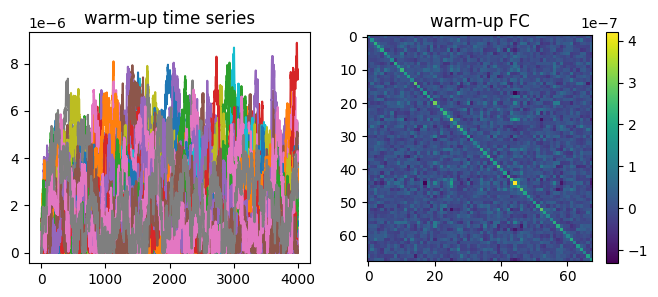

In [13]:
fig,(ax1,ax2,)=plt.subplots(1,2,figsize=(8,3))

ax1.set_title('warm-up time series')
ax1.plot(warmup_output[0,:,:])

# test the calculation of FC
ax2.set_title('warm-up FC')
X = bm.normalize(warmup_output,axis=1)
warmup_FC = bm.matmul(X.transpose(0,2,1),X)/duration
img = ax2.imshow(warmup_FC[0,:,:])
fig.colorbar(img)

plt.show()

Resting-state warm-up (no input)

In [14]:
# inter-trial-interval(iti) resting-state running function
@bm.jit
def run_rest(duration=(1.5+2)): # unit of duration is seconds：1.5s是完成刺激trial, 再加2s作为从noise input到稳定状态的时间
    runner = bp.DSRunner(model, progress_bar=False, numpy_mon_after_run=False)
    return runner.run(duration=duration, reset_state=False)

(7000, 68)
(7000, 68)


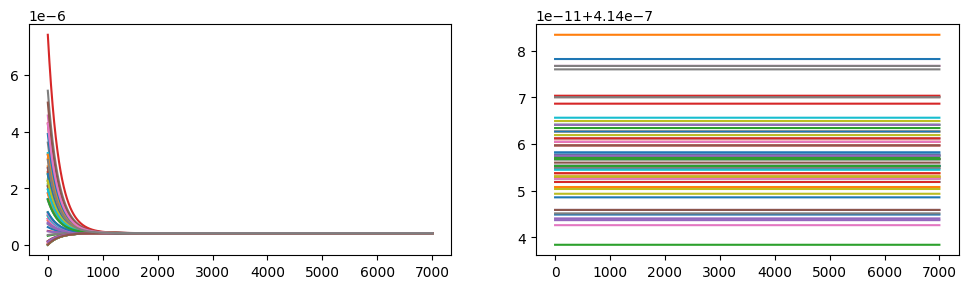

In [15]:
_,(ax1,ax2)=plt.subplots(1,2,figsize=(12,3))

warmup_output = run_rest()[0,:,:]
print(warmup_output.shape)
ax1.plot(warmup_output)

warmup_output = run_rest()[0,:,:]
print(warmup_output.shape)
ax2.plot(warmup_output)
plt.show()

# Training data prepare (based on FC)

In [16]:
tr_FC,tr_noiseinput,tr_mask_FC=get_training_data_FC(FC,Batch_size,duration,N,bm.dt,epsi=1e-6,seed=123)

rng=bm.random.RandomState(123)
noiseinput_generator=def_noiseinput_generator(rng,Batch_size,duration,N,bm.dt)

/tmp/ipykernel_2209000/4128299450.py:5: UserWarning: Adding colorbar to a different Figure <Figure size 1800x300 with 5 Axes> than <Figure size 800x300 with 3 Axes> which fig.colorbar is called on.
  fig.colorbar(img)
/tmp/ipykernel_2209000/4128299450.py:9: UserWarning: Adding colorbar to a different Figure <Figure size 1800x300 with 6 Axes> than <Figure size 800x300 with 3 Axes> which fig.colorbar is called on.
  fig.colorbar(img)
/tmp/ipykernel_2209000/4128299450.py:13: UserWarning: Adding colorbar to a different Figure <Figure size 1800x300 with 7 Axes> than <Figure size 800x300 with 3 Axes> which fig.colorbar is called on.
  fig.colorbar(img)
/tmp/ipykernel_2209000/4128299450.py:17: UserWarning: Adding colorbar to a different Figure <Figure size 1800x300 with 8 Axes> than <Figure size 800x300 with 3 Axes> which fig.colorbar is called on.
  fig.colorbar(img)


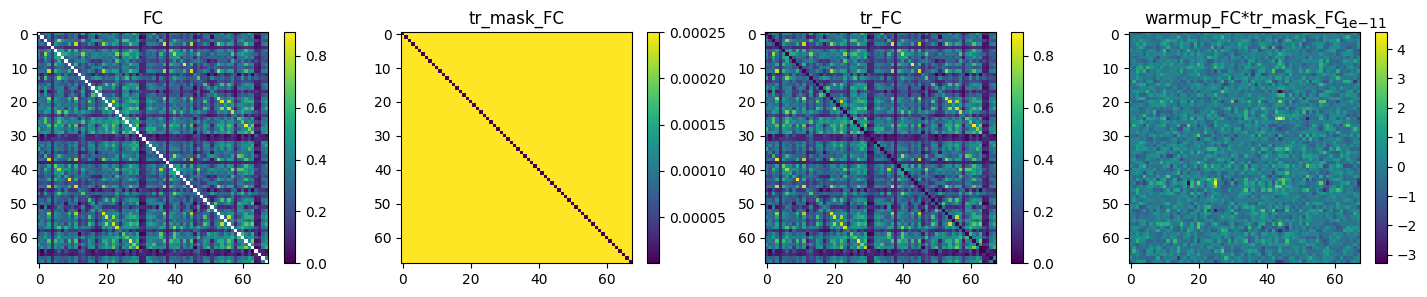

In [17]:
_, (ax1,ax2,ax3,ax4) = plt.subplots(1,4,figsize=(18,3))

ax1.set_title('FC')
img=ax1.imshow(FC)
fig.colorbar(img)

ax2.set_title('tr_mask_FC')
img = ax2.imshow(tr_mask_FC[0,:,:])
fig.colorbar(img)

ax3.set_title('tr_FC')
img = ax3.imshow(tr_FC[0,:,:])
fig.colorbar(img)

ax4.set_title('warmup_FC*tr_mask_FC')
img = ax4.imshow((warmup_FC*tr_mask_FC)[0,:,:])
fig.colorbar(img)

plt.show()

# Training data prepare (based on f-tract)

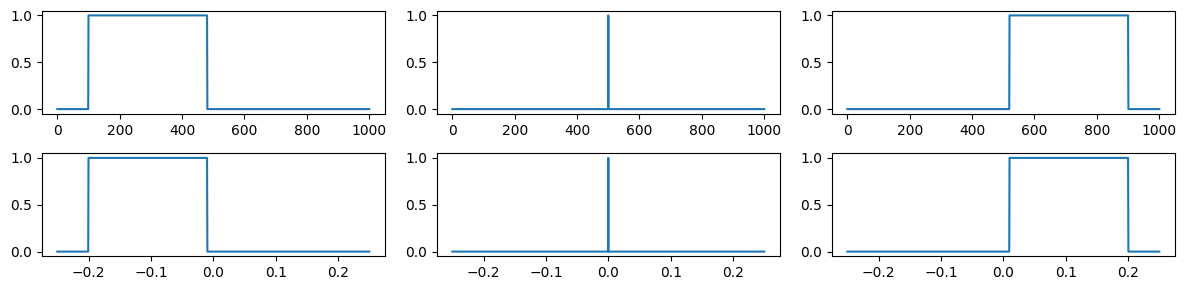

In [18]:
if EC_if_have_ITI:# 前后200ms用于计算loss的时间段作为输入，剩余的静息态由inter-trial-interval来完成，节约计算量
    ts,stim_onset,pre_period,pos_period = get_stim_timing(bm.dt,.25,.25) # 刺激tial为0.5s

else: # 2s秒钟全时间段作为输入
    ts,stim_onset,pre_period,pos_period = get_stim_timing(bm.dt,)

_,axs=plt.subplots(2,3,figsize=(12,3))
axs[0,0].plot(pre_period)
axs[0,1].plot(ts==0)
axs[0,2].plot(pos_period)
axs[1,0].plot(ts,pre_period)
axs[1,1].plot(ts,ts==0)
axs[1,2].plot(ts,pos_period)
plt.tight_layout();plt.show()

In [19]:
tr_EC,tr_stiminput,tr_mask_node,tr_mask_diag,tr_mask_pre,tr_mask_pos,tr_mask_time=get_training_data_EC(
    N, ftract_ctx, (ts,stim_onset,pre_period,pos_period), if_delete_ALLmaskedNodes=False, if_add_epsi_to_zeros=False, epsi=1e-5)

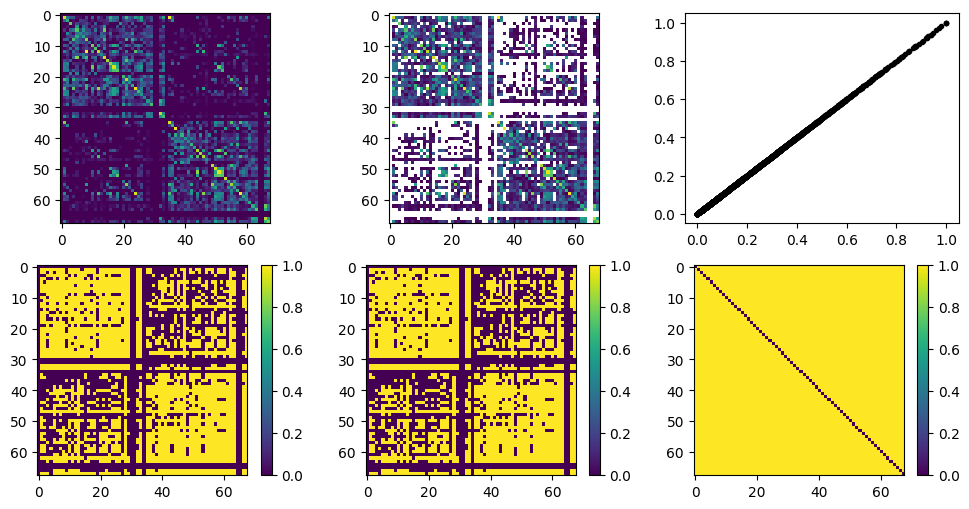

In [20]:
fig,axs=plt.subplots(2,3,figsize=(12,6))
axs[0,0].imshow(tr_EC.T)
axs[0,1].imshow(ftract_ctx)
axs[0,2].plot(tr_EC.T,ftract_ctx,'k.')

img=axs[1,0].imshow(tr_mask_node.mean(axis=1).T)
fig.colorbar(img)

img=axs[1,1].imshow(~np.isnan(ftract_ctx))
fig.colorbar(img)

img=axs[1,2].imshow(tr_mask_diag.mean(axis=1))
fig.colorbar(img)

## Training

prepare

In [21]:
bm.random.seed(123)
np.random.seed(123)

In [22]:
# model.reset_state(batch_size=Batch_size)
print(model.rnnLayer.S.shape)

(68, 68)


In [23]:
# move data to GPU
tr_noiseinput = bm.asarray(tr_noiseinput).cuda()
tr_FC = bm.asarray(tr_FC).cuda()
tr_mask_FC = bm.asarray(tr_mask_FC).cuda()

# move data to GPU
tr_stiminput = bm.asarray(tr_stiminput).cuda()
tr_EC        = bm.asarray(tr_EC).cuda()
tr_mask_time = bm.asarray(tr_mask_time).cuda()
tr_mask_node = bm.asarray(tr_mask_node).cuda()
tr_mask_diag = bm.asarray(tr_mask_diag).cuda()

Loss and training functions

In [24]:
loss_fun_EC = get_loss_fun_EC(model,EC_architecture)

loss_fun_FC = get_loss_fun_FC(model, N, sigma, FC_losstype, if_train_sigma)

def loss_fun_hybird(EC_inputs, EC_target, EC_masks, FC_inputs, FC_target, FC_masks):
    return EC_FC_loss_ratio*loss_fun_EC(EC_inputs, EC_target, EC_masks) + (1-EC_FC_loss_ratio)*loss_fun_FC(FC_inputs, FC_target, FC_masks)

In [25]:
# 确定训练参数
train_dict = model.train_vars().unique()
train_dict.update(loss_fun_FC.train_vars().unique())
print('train_dict:',train_dict)

if optimize_method == 'Adam':
    optim_func = bp.optim.Adam

grad_fun_hybird,train_hybird = get_train_fun(train_dict,loss_fun_hybird,optim_func,lr,if_largerLRforW,scale_largerLRforW,clip_epsilon=1e5)
# g,l=grad_fun_hybird(tr_stiminput, tr_EC, (tr_mask_time, tr_mask_node, tr_mask_diag),tr_noiseinput, tr_FC, tr_mask_FC) # test
# g,l=train_hybird(tr_stiminput, tr_EC, (tr_mask_time, tr_mask_node, tr_mask_diag),tr_noiseinput, tr_FC, tr_mask_FC) 

train_dict: {'DecoModel0.G': TrainVar(value=Array(1.), dtype=float32), 'DecoModel0.I': TrainVar(value=Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
                      0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
                      0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
                      0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],      dtype=float32),
         dtype=float32), 'DecoModel0.w': TrainVar(value=Array([-32., -32., -32., -32., -32., -32., -32., -32., -32., -32., -32.,
                      -32., -32., -32., -32., -32., -32., -32., -32., -32., -32., -32.,
                      -32., -32., -32., -32., -32., -32., -32., -32., -32., -32., -32.,
                      -32., -32., -32., -32., -32., -32., -32., -32., -32., -32., -32.,
                      -32., -32., -32., -32., -32., -32., -32., -32., -32., -32., -32.,
                      -32., -32., -32., -32., -32.

Start training

In [26]:
%%time

epoch_loss=np.zeros((epoch_N,))

epoch_G=np.zeros((epoch_N,))
epoch_w=np.zeros((epoch_N,N))
epoch_I=np.zeros((epoch_N,N))
epoch_a=np.zeros((epoch_N,))
epoch_sigma=np.zeros((epoch_N,N))

epoch_grad_G=np.zeros((epoch_N,))
epoch_grad_w=np.zeros((epoch_N,N))
epoch_grad_I=np.zeros((epoch_N,N))
epoch_grad_a=np.zeros((epoch_N,))
epoch_grad_sigma=np.zeros((epoch_N,N))

epoch_grad_dict = {
    "DecoModel0.G":epoch_grad_G,
    "DecoModel0.w":epoch_grad_w,
    "DecoModel0.I":epoch_grad_I,
    "outLinear0.a":epoch_grad_a,
    "loss_function_FC0.sigma":epoch_grad_sigma,
}

for epoch_i in range(epoch_N): # full-batch FC training
    

    if EC_if_have_ITI: run_rest() # inter-trial-interval(iti) resting-state running function

    ids = np.arange(tr_stiminput.shape[0])
    np.random.shuffle(ids)

    tr_noiseinput = noiseinput_generator()# tr_noiseinput.value = bm.random.randn(Batch_size, duration, N)*bm.sqrt(bm.dt) # (batch,time,node) 只需要1s

    grads, loss = train_hybird(tr_stiminput[ids,:,:], tr_EC[ids,:], (tr_mask_time[ids,:,:], tr_mask_node[ids,:,:], tr_mask_diag[ids,:,:]),tr_noiseinput, tr_FC, tr_mask_FC) 
    epoch_loss[epoch_i]=loss

    # appending results of parameters
    epoch_G[epoch_i]=np.asarray(model.rnnLayer.G)
    epoch_w[epoch_i,:]=np.asarray(model.rnnLayer.w)
    epoch_I[epoch_i,:]=np.asarray(model.rnnLayer.I)
    epoch_sigma[epoch_i,:]=np.asarray(bm.abs(loss_fun_FC.sigma))

    try: 
        epoch_a[epoch_i]=np.asarray(model.outLayer.a)
    except: 
        pass

    for key in grads.keys():
        epoch_grad_dict[key][epoch_i]=np.asarray(grads[key])


    # print
    if epoch_i<20 or (epoch_i+1)%100==0 :
        print(
            epoch_i, 
            '| Loss=',epoch_loss[epoch_i],
            "| G=",epoch_G[epoch_i],                "Grad(G)=",bm.abs(epoch_grad_G[epoch_i]).max(),
            '| w=',epoch_w[epoch_i].mean(),         "Grad(w)=",bm.abs(epoch_grad_w[epoch_i]).max(),
            "| I=",epoch_I[epoch_i].mean(),         "Grad(I)=",bm.abs(epoch_grad_I[epoch_i]).max(),
            "| sigma=",epoch_sigma[epoch_i].mean(), "Grad(sigma)=",np.abs(epoch_grad_sigma[epoch_i]).max(),
            "| a=",epoch_a[epoch_i],                "Grad(a)=",bm.abs(epoch_grad_a[epoch_i]).max(),
        )

0 | Loss= 0.04793287813663483 | G= 0.9500012993812561 Grad(G)= 0.0064948048 | w= -31.997248649597168 Grad(w)= 1.3101374e-05 | I= 0.035815438680241216 Grad(I)= 0.12980947 | sigma= 0.04993905926890233 Grad(sigma)= 0.0007254178635776043 | a= 1.0 Grad(a)= 0.0


1 | Loss= 0.04849620535969734 | G= 0.8896335363388062 Grad(G)= 0.0025959099 | w= -32.0019910475787 Grad(w)= 7.6079023e-06 | I= 0.05043157053125255 Grad(I)= 0.038017996 | sigma= 0.03302618603715125 Grad(sigma)= 0.0007095425389707088 | a= 1.0 Grad(a)= 0.0


2 | Loss= 0.047833409160375595 | G= 0.8429183959960938 Grad(G)= 0.0010014798 | w= -32.017266161301556 Grad(w)= 1.9841578e-05 | I= 0.06099658112918191 Grad(I)= 0.03140871 | sigma= 0.023710643708267632 Grad(sigma)= 0.0021788827143609524 | a= 1.0 Grad(a)= 0.0


3 | Loss= 0.04804248362779617 | G= 0.830305278301239 Grad(G)= 0.0039020854 | w= -32.03280207690071 Grad(w)= 1.522975e-05 | I= 0.07381783465526122 Grad(I)= 0.008907375 | sigma= 0.04412321866616634 Grad(sigma)= 0.0014092609053477645 | a= 1.0 Grad(a)= 0.0


4 | Loss= 0.04830265790224075 | G= 0.8303869366645813 Grad(G)= 0.0018440866 | w= -32.048456135918116 Grad(w)= 5.4030188e-05 | I= 0.08617049829541322 Grad(I)= 0.00663192 | sigma= 0.060275907696717805 Grad(sigma)= 0.0018247002735733986 | a= 1.0 Grad(a)= 0.0


5 | Loss= 0.048547662794589996 | G= 0.8180268406867981 Grad(G)= 0.0021210304 | w= -32.07152310539694 Grad(w)= 0.00022261713 | I= 0.0919111001661376 Grad(I)= 0.007325881 | sigma= 0.07190890808808892 Grad(sigma)= 0.002559891203418374 | a= 1.0 Grad(a)= 0.0


... (110 outputs left out)

9699 | Loss= 0.014047359116375446 | G= 1.7232800722122192 Grad(G)= 0.0011004389 | w= -25.896666819558423 Grad(w)= 3.2188094e-05 | I= 0.9373831976451638 Grad(I)= 0.00029196576 | sigma= 2.6719743038103094 Grad(sigma)= 0.0005966275930404663 | a= 1.0 Grad(a)= 0.0


9799 | Loss= 0.01404501311480999 | G= 1.7270077466964722 Grad(G)= 9.153028e-05 | w= -25.935201522182016 Grad(w)= 4.208427e-06 | I= 0.9345169703284388 Grad(I)= 4.146051e-05 | sigma= 2.6948351607737577 Grad(sigma)= 0.00025244790595024824 | a= 1.0 Grad(a)= 0.0


9899 | Loss= 0.01407052855938673 | G= 1.7294831275939941 Grad(G)= 0.00036621236 | w= -25.983973233138812 Grad(w)= 7.58053e-06 | I= 0.9360419628621244 Grad(I)= 0.000104980674 | sigma= 2.7170731060271947 Grad(sigma)= 0.0004799744638148695 | a= 1.0 Grad(a)= 0.0


9999 | Loss= 0.014083989895880222 | G= 1.7252401113510132 Grad(G)= 0.0013089676 | w= -26.004185815067853 Grad(w)= 8.028588e-06 | I= 0.9469039142131805 Grad(I)= 7.470693e-05 | sigma= 2.7389360415716726 Grad(sigma)= 0.0003418243722990155 | a= 1.0 Grad(a)= 0.0
CPU times: user 41min 21s, sys: 27min 49s, total: 1h 9min 11s
Wall time: 1h 9min 37s


Plot and save

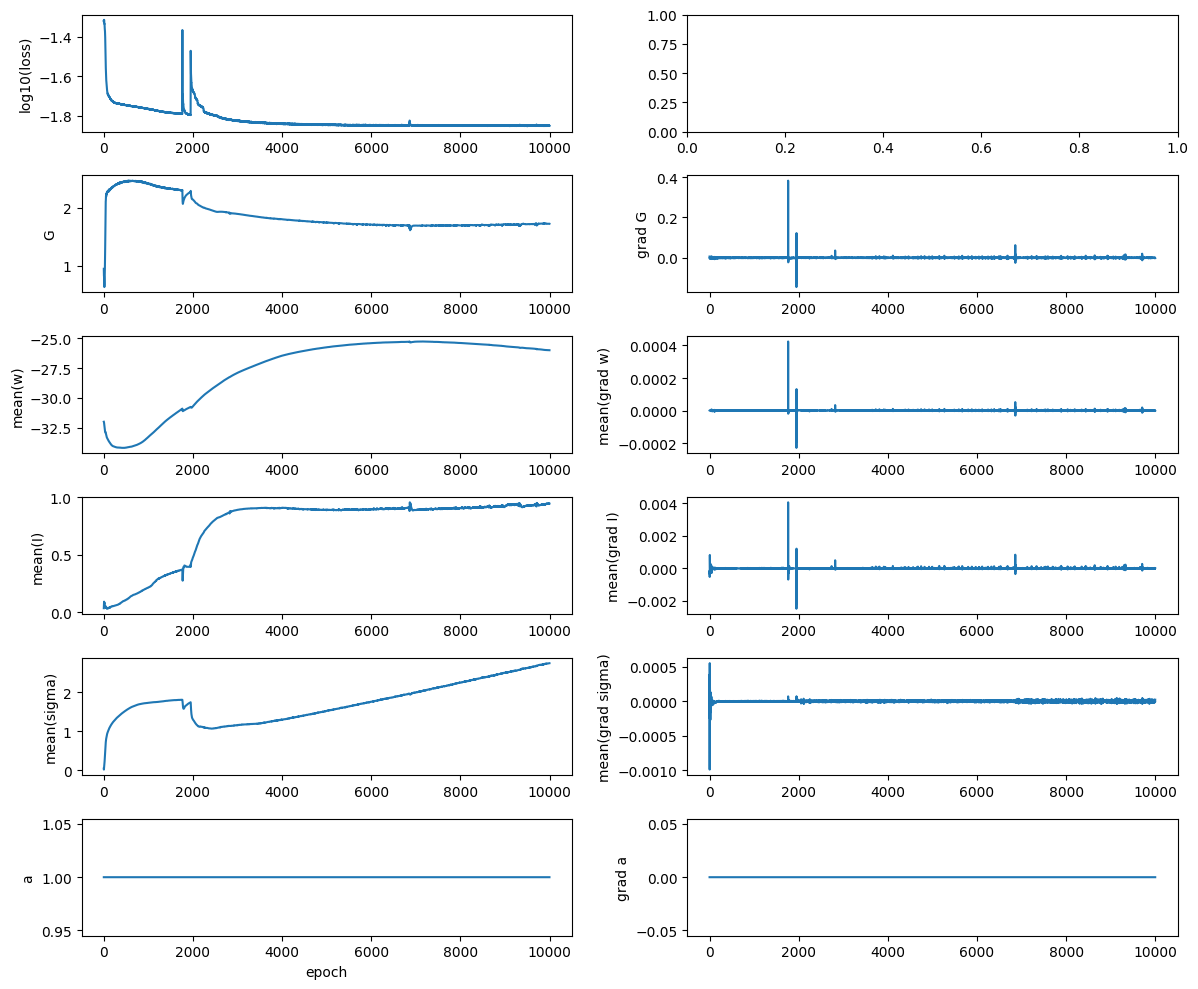

In [27]:
_,axs = plt.subplots(6,2,figsize=(12,10))

axs[0,0].plot(np.log10(epoch_loss))
axs[0,0].set_ylabel("log10(loss)")

axs[1,0].plot(epoch_G)
axs[1,0].set_ylabel("G")

axs[2,0].plot(np.mean(epoch_w,axis=1))
axs[2,0].set_ylabel("mean(w)")

axs[3,0].plot(np.mean(epoch_I,axis=1))
axs[3,0].set_ylabel("mean(I)")

axs[4,0].plot(np.mean(epoch_sigma,axis=1))
axs[4,0].set_ylabel("mean(sigma)")

axs[5,0].plot(epoch_a)
axs[5,0].set_ylabel("a")
axs[5,0].set_xlabel("epoch")

axs[1,1].plot(epoch_grad_G)
axs[1,1].set_ylabel("grad G")

axs[2,1].plot(np.mean(epoch_grad_w,axis=1))
axs[2,1].set_ylabel("mean(grad w)")

axs[3,1].plot(np.mean(epoch_grad_I,axis=1))
axs[3,1].set_ylabel("mean(grad I)")

axs[4,1].plot(np.mean(epoch_grad_sigma,axis=1))
axs[4,1].set_ylabel("mean(grad sigma)")

axs[5,1].plot(epoch_grad_a)
axs[5,1].set_ylabel("grad a")

plt.tight_layout()
plt.show()

In [28]:
display(model.train_vars())
display(loss_fun_FC.train_vars())

{'DecoModel0.G': TrainVar(value=Array(1.7252401), dtype=float32),
 'DecoModel0.I': TrainVar(value=Array([ 3.3258421 , -0.03286266,  0.58616734,  0.767861  , -0.03017831,
                        0.08126684,  1.6897041 ,  1.0506351 , -0.42774528,  1.8306233 ,
                        0.5073427 ,  2.9524915 ,  0.3480586 ,  2.5156274 , -0.4823426 ,
                        1.1156112 , -0.13588113, -0.3485513 , -0.05778493,  0.4191129 ,
                        0.31962135, -0.43765965,  1.3727727 ,  1.5081117 ,  0.51303124,
                        1.8314738 ,  3.2607148 ,  3.9252834 ,  2.176172  ,  0.48380363,
                       -1.0559728 , -1.0802379 , -0.10679132,  1.6076727 ,  1.8798723 ,
                        0.01177694,  0.68894637, -0.90086144,  0.11150374, -0.03651679,
                        3.1996763 ,  0.5553839 ,  1.8995813 ,  1.7327399 ,  0.40312165,
                        1.2481198 ,  0.728143  ,  1.9729514 , -0.01994134,  0.72925186,
                       -0.29301375, -0

{'loss_function_FC0.sigma': TrainVar(value=Array([ 6.48456719e-03, -6.44359350e-01,  2.16166735e-01,  3.77641758e-04,
                        3.36765060e+01,  1.61941424e-01,  2.21173704e-01,  2.20841512e-01,
                        3.45265436e+00,  1.18010327e-01,  7.73409843e-01,  1.30751982e-01,
                        3.10436010e+00,  2.19595224e-01,  5.29098451e-01,  3.27507585e-01,
                       -3.06361437e-01,  6.04895651e-01,  3.59692842e-01, -9.08369489e-04,
                       -1.47785380e-01,  4.77527022e-01,  1.88463971e-01,  3.26088578e-01,
                       -2.33078527e+00, -3.74736428e-01,  3.81371677e-01,  1.66213378e-01,
                       -8.47361237e-02, -1.09351546e-01,  7.54303741e+00,  5.40720749e+01,
                        3.95847224e-02,  4.07601714e-01,  1.28614623e-03,  6.91069007e-01,
                       -2.15908274e-01,  1.63268477e-01,  4.98791466e+01, -1.01002336e-01,
                       -1.73865363e-01,  1.77277267e-01,  3.981

In [29]:
# save
states = {
#初值：
'G': G, 
'w': w,
'I': I,
'sigma':sigma,
# TrainVar setting
'TrainVar_list' : TrainVar_list,
'if_train_sigma':if_train_sigma,
#超参：
'epoch_N':epoch_N,
'lr':lr,
'optimize_method':optimize_method,
'scale_largerLRforW':scale_largerLRforW, # scale LR of W
'EC_FC_loss_ratio':EC_FC_loss_ratio,
# FC 相关
'FC_losstype':FC_losstype, 
'FC_architecture':FC_architecture,
'Batch_size':Batch_size,
'duration':duration, # input noise时长
# EC 相关
'EC_architecture':EC_architecture,
'EC_if_have_ITI':EC_if_have_ITI,
#训练结果：
'model': model.state_dict(), # save the state dict of the network in the checkpoint
'loss_fun_FC': loss_fun_FC.state_dict(), # FC's loss fun with training results of sigma
#训练过程：
'epoch_loss':epoch_loss, 
'epoch_G':epoch_G,
'epoch_w':epoch_w,
'epoch_I':epoch_I,
'epoch_a':epoch_a,
'epoch_sigma':epoch_sigma,
'epoch_grad_G':epoch_grad_G,
'epoch_grad_w':epoch_grad_w,
'epoch_grad_I':epoch_grad_I,
'epoch_grad_a':epoch_grad_a,
'epoch_grad_sigma':epoch_grad_sigma,
}

bp.checkpoints.save_pytree(save_path+save_file+'.bp', states) 

Saving checkpoint into /data/xyc/codes/iEEG_network/4_model_BrainPy/2trainBPTT_Deco_EndToEnd_ftract_and_FC/HybirdTraining/trainingHybird/G1.0_w-32.0_I0.0_sigma1e-05_Adam_lr0.05_wLRx1_epo10k_lossratio0.75.bp
